1. Setup Dataset Files

In [ ]:
with open('grocery_prices.csv', 'w') as f:
    f.write("Item,Retailer_A,Retailer_B,Retailer_C\nMilk,3.50,3.45,\nBread,,2.10,2.15\nEggs,2.99,2.99,3.05\nCheese,4.50,,4.60\nApples,3.20,3.25,3.15")

with open('dnd_entities.csv', 'w') as f:
    f.write("Entity_Name,Role,Origin\nArthur,Adventurer,Earth\nSystem,Dungeon Master,Void\nKenji,Adventurer,Earth\nLyra,Adventurer,Isekai_Realm\nGarrick,NPC,Isekai_Realm\nKael,Adventurer,Earth")

print("Datasets created successfully!")

Datasets created successfully!


2. Section 1 - NumPy (Q1 - Q10)

In [ ]:
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


print("Q1 - NumPy Version:", np.__version__)


arr_1d = np.arange(1, 20)
print("\nQ2 - Odd numbers:", arr_1d[arr_1d % 2 != 0])

bool_arr = arr_1d > 5
print("\nQ3 - Boolean array (>5):", bool_arr)


rand_ints = np.random.randint(0, 100, size=15)
print("\nQ4 - Random array:", rand_ints)
print("Maximum value:", np.max(rand_ints))


print("\nQ5 - Index of minimum value:", np.argmin(rand_ints))


rand_floats_2d = np.random.rand(3, 3)
print("\nQ6 - 3x3 random floats:\n", rand_floats_2d)


diag_arr = np.zeros((4, 4))
np.fill_diagonal(diag_arr, 5)
print("\nQ7 - Diagonal array:\n", diag_arr)


arr_3x4 = np.arange(12).reshape(3, 4)
print("\nQ8 - Sum of each row:", np.sum(arr_3x4, axis=1))


print("\nQ9 - Horizontally flipped array:\n", np.fliplr(arr_3x4))


print("\nQ10 - Cumulative product of rows:\n", np.cumprod(arr_3x4 + 1, axis=1))

Q1 - NumPy Version: 2.1.3

Q2 - Odd numbers: [ 1  3  5  7  9 11 13 15 17 19]

Q3 - Boolean array (>5): [False False False False False  True  True  True  True  True  True  True
  True  True  True  True  True  True  True]

Q4 - Random array: [53 23 20 92 29  0 97 44 25 92 77  6 28 66 74]
Maximum value: 97

Q5 - Index of minimum value: 5

Q6 - 3x3 random floats:
 [[0.54230233 0.10019946 0.19356126]
 [0.95244897 0.33611173 0.70801887]
 [0.97199543 0.71656611 0.623091  ]]

Q7 - Diagonal array:
 [[5. 0. 0. 0.]
 [0. 5. 0. 0.]
 [0. 0. 5. 0.]
 [0. 0. 0. 5.]]

Q8 - Sum of each row: [ 6 22 38]

Q9 - Horizontally flipped array:
 [[ 3  2  1  0]
 [ 7  6  5  4]
 [11 10  9  8]]

Q10 - Cumulative product of rows:
 [[    1     2     6    24]
 [    5    30   210  1680]
 [    9    90   990 11880]]


3. Section 1 - NumPy (Q11 - Q12)

In [ ]:
dataset = np.genfromtxt('grocery_prices.csv', delimiter=',', skip_header=1)

col_means = np.nanmean(dataset, axis=0)
inds = np.where(np.isnan(dataset))
dataset[inds] = np.take(col_means, inds[1])

print("Q11 - Cleaned numerical dataset:\n", dataset)


text_column = np.genfromtxt('dnd_entities.csv', delimiter=',', dtype=str, skip_header=1, usecols=(2,))
unique_texts = np.unique(text_column)

print("\nQ12 - Unique text values in the column:", unique_texts)

Q11 - Cleaned numerical dataset:
 [[   nan 3.5    3.45   3.2375]
 [   nan 3.5475 2.1    2.15  ]
 [   nan 2.99   2.99   3.05  ]
 [   nan 4.5    2.9475 4.6   ]
 [   nan 3.2    3.25   3.15  ]]

Q12 - Unique text values in the column: ['Earth' 'Isekai_Realm' 'Void']


4. Section 2 - Pandas

Q1 - First 10 rows:
    carat        cut color clarity  depth  table  price     x     y     z
0   0.23      Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21    Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23       Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29    Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31       Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
5   0.24  Very Good     J    VVS2   62.8   57.0    336  3.94  3.96  2.48
6   0.24  Very Good     I    VVS1   62.3   57.0    336  3.95  3.98  2.47
7   0.26  Very Good     H     SI1   61.9   55.0    337  4.07  4.11  2.53
8   0.22       Fair     E     VS2   65.1   61.0    337  3.87  3.78  2.49
9   0.23  Very Good     H     VS1   59.4   61.0    338  4.00  4.05  2.39

Q2 - Selected columns:
    carat      cut  price
0   0.23    Ideal    326
1   0.21  Premium    326
2   0.23     Good    327
3   0.29  Premium    334
4   0.31     Good    335



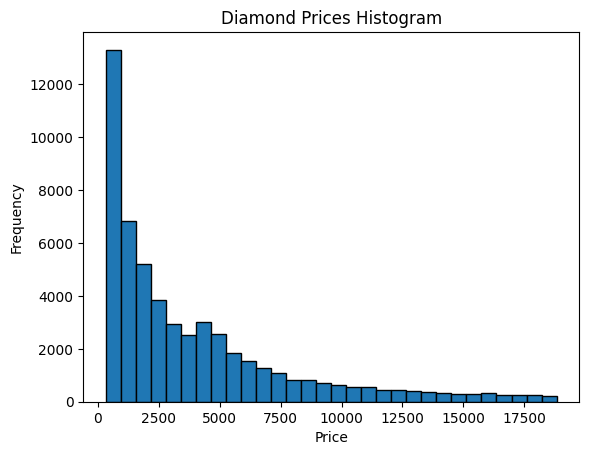

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
diamonds_df = pd.read_csv(url)
print("Q1 - First 10 rows:\n", diamonds_df.head(10))

selected_cols = diamonds_df[['carat', 'cut', 'price']]
print("\nQ2 - Selected columns:\n", selected_cols.head())

diamonds_df['Price-Quality'] = diamonds_df['price'].astype(str) + " - " + diamonds_df['cut']
print("\nQ3 - New 'Price-Quality' series:\n", diamonds_df['Price-Quality'].head())

print("\nQ4 - Unique values per column:\n", diamonds_df.nunique())

print("\nQ5 - Summary of numerical columns:\n", diamonds_df.describe())

dropped_df = diamonds_df.drop(index=range(5))
reset_df = dropped_df.reset_index(drop=True)
print("\nQ6 - DataFrame with reset index:\n", reset_df.head())


print("\nQ7 - Plotting histogram of the 'price' column...")
diamonds_df['price'].plot(kind='hist', bins=30, edgecolor='black', title='Diamond Prices Histogram')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()